# Algoritmos de optimización - Seminario

Nombre y Apellidos:   Lucas Ivan Tamara Trejo

Url: https://github.com/lucastamaraucv/PROYECTO-AG

Problema:
> 1. Sesiones de doblaje
>2. Organizar los horarios de partidos de La Liga
>3. Combinar cifras y operaciones

Descripción del problema:(copiar enunciado)

**1. Sesiones de doblaje:** Se precisa coordinar el doblaje de una película. Los actores del doblaje deben coincidir en las tomas en las que sus personajes aparecen juntos en las diferentes tomas. Los actores de doblaje cobran todos la misma cantidad por cada día que deben desplazarse hasta el estudio de grabación, independientemente del número de tomas que se graben. No es posible grabar más de 6 tomas por día. El objetivo es planificar las sesiones por día de manera que el gasto por los servicios de los actores de doblaje sea el menor posible. Número de actores: 10. Número de tomas: 30.

**2. Organizar los horarios de partidos de La Liga:** Se pretende organizar los horarios de los partidos de liga de cada jornada de forma que se maximice la audiencia. Horarios disponibles: Viernes 20h; Sábado 12,16,18,20h; Domingo 12,16,18,20h; Lunes 20h. Hay 3 equipos de categoría A, 11 de categoría B y 6 de categoría C, con una audiencia base por combinación de categorías, coeficientes de reducción según el horario, y penalización por coincidencia de horarios. Debe asignarse obligatoriamente un partido el viernes y uno el lunes.

**3. Combinar cifras y operaciones:** Se dispone de las 9 cifras del 1 al 9 (excluyendo el cero) y de los 4 signos básicos de las operaciones fundamentales: suma(+), resta(-), multiplicación(*) y división(/). Deben combinarse alternativamente sin repetir ninguno de ellos para obtener una cantidad dada. Ejemplo para obtener el 4: 4+2-6/3*1 = 4.

(*) La respuesta es obligatoria

In [1]:
# === Configuración y datos comunes a los 3 problemas ===
import pandas as pd
import matplotlib.pyplot as plt

def fmt_dec(x, decimales=2):
    """Formatea un número decimal con coma (convención de Perú), sin separador de miles."""
    return f"{x:.{decimales}f}".replace(".", ",")

def print_banner(texto):
    """Imprime el texto en una caja con bordes Unicode, para que resalte en la consola/PDF."""
    ancho = len(texto) + 2
    print("┌" + "─" * ancho + "┐")
    print("│ " + texto + " │")
    print("└" + "─" * ancho + "┘")

import numpy as np
import itertools
import random
import math
from math import comb, factorial
from functools import lru_cache

# --- Problema 1: Sesiones de doblaje (datos reales desde el Google Sheet del enunciado) ---
SHEET_ID = "1Ipn6IrbQP4ax8zOnivdBIw2lN0JISkJG4fXndYd27U0"
url = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid=0"
df = pd.read_csv(url, skiprows=1, index_col=0)
df = df.drop(columns=[c for c in df.columns if 'Unnamed' in c or c == 'Total'], errors='ignore')
df = df.dropna(how='all')
df = df[pd.to_numeric(df.index, errors='coerce').notna()]  # descarta la fila "TOTAL" final
df.index = df.index.astype(int)
df.columns = [int(c) for c in df.columns]

tomas_bitmask = {
    toma: int(''.join(str(int(v)) for v in fila), 2)
    for toma, fila in df.iterrows()
}

def coste_dia(dia, tomas_bitmask):
    mask = 0
    for t in dia:
        mask |= tomas_bitmask[t]
    return bin(mask).count('1')

def coste_particion(particion, tomas_bitmask):
    return sum(coste_dia(dia, tomas_bitmask) for dia in particion)

# --- Problema 2: Horarios de La Liga ---
HORARIOS = ["V20", "S12", "S16", "S18", "S20", "D12", "D16", "D18", "D20", "L20"]
HORARIOS_LIBRES = ("S12", "S16", "S18", "S20", "D12", "D16", "D18", "D20")

AUDIENCIA_BASE = {
    frozenset(["A", "A"]): 2.0, frozenset(["A", "B"]): 1.3, frozenset(["A", "C"]): 1.0,
    frozenset(["B", "B"]): 0.9, frozenset(["B", "C"]): 0.75, frozenset(["C", "C"]): 0.47,
}
COEF_HORARIO = {
    "V20": 0.4, "L20": 0.4, "S12": 0.55, "S16": 0.7, "S18": 0.8, "S20": 1.0,
    "D12": 0.45, "D16": 0.75, "D18": 0.85, "D20": 1.0,
}
PENALIZACION_COINCIDENCIA = {0: 0.0, 1: 0.25, 2: 0.45, 3: 0.60, 4: 0.70, 5: 0.75, 6: 0.78, 7: 0.80, 8: 0.80}

def audiencia_base(cat1, cat2):
    return AUDIENCIA_BASE[frozenset([cat1, cat2])]

def audiencia_jornada(partidos, asignacion):
    conteo_horario = {}
    for h in asignacion:
        conteo_horario[h] = conteo_horario.get(h, 0) + 1
    total = 0.0
    for (cat1, cat2), horario in zip(partidos, asignacion):
        coincidencias = conteo_horario[horario] - 1
        penal = PENALIZACION_COINCIDENCIA[min(coincidencias, 8)]
        total += audiencia_base(cat1, cat2) * COEF_HORARIO[horario] * (1 - penal)
    return total

partidos_ejemplo = [("B","A"), ("B","A"), ("C","C"), ("B","A"), ("C","C"),
                    ("B","C"), ("B","B"), ("B","B"), ("B","C"), ("B","B")]
horarios_ejemplo = ["V20","S12","S16","S18","S20","D16","D16","D18","D20","L20"]

# --- Problema 3: Combinar cifras y operaciones ---
def construir_expresion(cifras, operadores):
    partes = [str(cifras[0])]
    for op, c in zip(operadores, cifras[1:]):
        partes.append(op)
        partes.append(str(c))
    return ''.join(partes)

def evaluar_incremental(cifras, operadores):
    total = 0.0
    signo = 1
    termino = cifras[0]
    for op, c in zip(operadores, cifras[1:]):
        if op == '+':
            total += signo * termino
            signo, termino = 1, c
        elif op == '-':
            total += signo * termino
            signo, termino = -1, c
        elif op == '*':
            termino *= c
        elif op == '/':
            termino /= c
    total += signo * termino
    return total

print("Datos y funciones base cargadas para los 3 problemas.")

Datos y funciones base cargadas para los 3 problemas.


(*)¿Cuantas posibilidades hay sin tener en cuenta las restricciones?<br>



¿Cuantas posibilidades hay teniendo en cuenta todas las restricciones.




Respuesta

**Problema 1 (Doblaje):** sin restricciones, la respuesta es B(30) = 846749014511809332450147. Con la restricción de máximo 6 tomas/día, baja a R(30) = 726391948970868949621309.

Agrupar las 30 tomas en días es contar particiones de un conjunto, y ambos números salen de la misma recurrencia R(n,k) = Σ C(n-1,i-1)·R(n-i,k), construida enteramente sobre combinaciones (ya vistas en el curso) aplicadas recursivamente: sin límite de bloque da B(30) — lo que la literatura matemática llama número de Bell, nombre que no aparece en el curso aunque sus piezas (combinaciones + recursión) sí — y con límite k=6 da R(30). El punto clave es que ninguno de los dos números es explorable a mano; por eso el resto del ejercicio pasa por diseñar algoritmos que no necesiten enumerar todo.

**Problema 2 (Liga):** sin restricciones, la respuesta es 10^10 = 10000000000 asignaciones. Con la restricción de 1 partido fijo en viernes y 1 en lunes, la respuesta es 10×9×8^8 = 1509949440.

Sin restricciones son 10 partidos, cada uno con 10 horarios posibles. Con la restricción se eligen esos 2 partidos entre los 10 y el resto se reparte entre las 8 franjas libres.

**Problema 3 (Cifras):** la respuesta es V(9,5)×4! = 15120×24 = 362880 expresiones posibles.

Al alternar cifra-operador-cifra-...-operador-cifra con los 4 operadores (todos, sin repetir), la expresión usa exactamente 5 de las 9 cifras — 4 operadores necesitan 5 operandos, ni uno más. Cuántas de esas dan resultado entero solo se sabe evaluándolas: la división rompe cualquier fórmula cerrada.

In [2]:
# --- Problema 1 ---
@lru_cache(maxsize=None)
def contar_particiones(n, k):
    """Nº de formas de agrupar n elementos en bloques no vacíos de tamaño <= k
    (construido enteramente con combinaciones C(n,k), ya vistas en el curso)."""
    if n == 0:
        return 1
    total = 0
    for i in range(1, min(n, k) + 1):
        total += comb(n - 1, i - 1) * contar_particiones(n - i, k)
    return total

n_tomas = len(df)
B_n = contar_particiones(n_tomas, n_tomas)   # sin límite de bloque -> número de Bell B(n)
R_n = contar_particiones(n_tomas, 6)         # con el límite real de 6 tomas/día
print(f"[Problema 1 - Doblaje] Sin restricciones: B({n_tomas}) = {B_n}")
print(f"[Problema 1 - Doblaje] Con restricciones: R({n_tomas}) = {R_n}")
print()

# --- Problema 2 ---
sin_restr_liga = 10 ** 10
con_restr_liga = 10 * 9 * (8 ** 8)
print(f"[Problema 2 - Liga] Sin restricciones: {sin_restr_liga}")
print(f"[Problema 2 - Liga] Con restricciones: {con_restr_liga}")
print()

# --- Problema 3 ---
def variaciones(n, r):
    return factorial(n) // factorial(n - r)

total_expresiones = variaciones(9, 5) * factorial(4)
print(f"[Problema 3 - Cifras] Expresiones posibles: {total_expresiones}")

[Problema 1 - Doblaje] Sin restricciones: B(30) = 846749014511809332450147
[Problema 1 - Doblaje] Con restricciones: R(30) = 726391948970868949621309

[Problema 2 - Liga] Sin restricciones: 10000000000
[Problema 2 - Liga] Con restricciones: 1509949440

[Problema 3 - Cifras] Expresiones posibles: 362880


Modelo para el espacio de soluciones<br>
(*) ¿Cual es la estructura de datos que mejor se adapta al problema? Argumentalo.(Es posible que hayas elegido una al principio y veas la necesidad de cambiar, arguentalo)


Respuesta

**Problema 1:** la estructura elegida es **bitmask** — cada toma como un entero de 10 bits, uno por actor. La matriz binaria actor×toma (pandas) sirve para cargar los datos, pero para el algoritmo se traduce a bitmask porque la unión de actores de un grupo de tomas pasa a ser un simple OR de bits, y contarlos es `bin(mask).count('1')` — mucho más rápido que operar con sets o listas.

**Problema 2:** la estructura elegida son tablas de consulta (diccionarios) más una lista de horarios como solución candidata. Cada partido es `(categoría_local, categoría_visitante)`, con 3 diccionarios para audiencia base, coeficiente de horario y penalización por coincidencia. Una solución completa es una lista de horarios, uno por partido.

**Problema 3:** la estructura elegida es el string evaluable con `eval()`. Python ya resuelve la precedencia de operadores, no hace falta reinventarlo. En la versión mejorada se cambia a listas de cifras/operadores evaluadas incrementalmente, evitando la construcción del string.

In [3]:
# Problema 1: ejemplo de bitmask
ejemplo_toma = df.index[0]
print("Problema 1 - Doblaje - bitmask toma", ejemplo_toma, "=", bin(tomas_bitmask[ejemplo_toma]))
print()

# Problema 2: ejemplo de tabla de consulta
audiencia_base_ejemplo = audiencia_base("B", "A")
print("Problema 2 - Liga - audiencia base B vs A:", fmt_dec(audiencia_base_ejemplo, 1), "Millones")
print()

# Problema 3: ejemplo de expresión
print("Problema 3 - Cifras - expresión de ejemplo:", construir_expresion([4, 2, 6, 3, 1], ['+', '-', '/', '*']))

Problema 1 - Doblaje - bitmask toma 1 = 0b1111100000

Problema 2 - Liga - audiencia base B vs A: 1,3 Millones

Problema 3 - Cifras - expresión de ejemplo: 4+2-6/3*1


Según el modelo para el espacio de soluciones<br>
(*)¿Cual es la función objetivo?

(*)¿Es un problema de maximización o minimización?

Respuesta

**Problema 1:** la función objetivo es Coste(P) = Σⱼ |A(Dⱼ)|, la suma por día del número de actores distintos que participan en las tomas de ese día (P = partición de las 30 tomas en días de ≤6 tomas). Es un problema de **minimización**, porque el enunciado pide explícitamente que "el gasto por los servicios de los actores de doblaje sea el menor posible" — se busca la partición que haga ese gasto lo más chico posible, no hay ningún valor que convenga aumentar.

**Problema 2:** la función objetivo es Audiencia = Σᵢ [Base(partidoᵢ) × Coef(horarioᵢ) × (1 − Penalización(coincidencias en horarioᵢ))], sumado sobre los 10 partidos de la jornada. Es un problema de **maximización**, porque el enunciado pide explícitamente "que maximice la audiencia" — acá el objetivo es el opuesto al de Doblaje: más audiencia es mejor, no hay ningún coste que minimizar.

**Problema 3:** la función objetivo busca el valor máximo alcanzable, el valor mínimo alcanzable, y el conjunto completo de enteros intermedios que realmente se pueden formar. No es max o min — es **ambos a la vez** (max + min + cobertura), porque el propio enunciado plantea las dos preguntas por separado ("¿qué valor máximo y mínimo se pueden obtener?"), sin pedir optimizar en un solo sentido.

In [4]:
# Problema 1: ejemplo de coste
print("Problema 1 - Doblaje - coste de un día con todas las tomas (ilustrativo):",
      coste_particion([list(df.index)], tomas_bitmask))
print()

# Problema 2: audiencia del ejemplo del enunciado
audiencia_ejemplo_liga = audiencia_jornada(partidos_ejemplo, horarios_ejemplo)
print("Problema 2 - Liga - audiencia del ejemplo:", fmt_dec(audiencia_ejemplo_liga, 2), "Millones")
print()

# Problema 3: evaluación de la expresión de ejemplo
resultado_ejemplo_cifras = evaluar_incremental([4, 2, 6, 3, 1], ['+', '-', '/', '*'])
print("Problema 3 - Cifras - evaluación incremental de 4+2-6/3*1 =", fmt_dec(resultado_ejemplo_cifras, 1))

Problema 1 - Doblaje - coste de un día con todas las tomas (ilustrativo): 10

Problema 2 - Liga - audiencia del ejemplo: 5,88 Millones

Problema 3 - Cifras - evaluación incremental de 4+2-6/3*1 = 4,0


Diseña un algoritmo para resolver el problema por fuerza bruta

Respuesta

**Problema 1:** backtracking que genera cada partición válida de las tomas en grupos ≤6 (fija la primera toma sin asignar y prueba todas las combinaciones de compañeras de grupo), calcula el coste de cada una y se queda con la mínima. Conviene advertir que esto solo es viable en un subconjunto pequeño (8 tomas): con las 30 tomas reales, el tamaño de R(30) lo hace inservible.

**Problema 2:** se prueban todas las asignaciones válidas (10×9 formas de fijar viernes y lunes, multiplicado por 8^(n-2) para el resto), evaluando la audiencia de cada una. Igual que en Doblaje, esto solo es viable en una jornada reducida (4 partidos).

**Problema 3:** en este caso la fuerza bruta sí es completamente viable, ya que 362880 expresiones es un número perfectamente manejable para una computadora. Se generan todas las variaciones de 5 cifras (de las 9) con todas las permutaciones de los 4 operadores, se evalúan con `eval()`, y se guardan los resultados enteros.

In [ ]:
# --- Problema 1: fuerza bruta (backtracking), demo en subconjunto de 8 tomas ---
def fuerza_bruta_doblaje(tomas, tomas_bitmask, max_dia=6):
    tomas = list(tomas)
    mejor_coste = [None]
    mejor_particion = [None]

    def backtrack(restantes, particion_actual, coste_actual):
        if not restantes:
            if mejor_coste[0] is None or coste_actual < mejor_coste[0]:
                mejor_coste[0] = coste_actual
                mejor_particion[0] = [list(d) for d in particion_actual]
            return
        if mejor_coste[0] is not None and coste_actual >= mejor_coste[0]:
            return
        primera = restantes[0]
        resto = restantes[1:]
        for tam in range(1, min(max_dia, len(restantes)) + 1):
            for companeras in itertools.combinations(resto, tam - 1):
                dia = (primera,) + companeras
                coste_este_dia = coste_dia(dia, tomas_bitmask)
                nuevos_restantes = [t for t in resto if t not in companeras]
                backtrack(nuevos_restantes, particion_actual + [dia], coste_actual + coste_este_dia)

    backtrack(tomas, [], 0)
    return mejor_particion[0], mejor_coste[0]

subset_bruta = list(df.index[:8])
particion_opt, coste_opt = fuerza_bruta_doblaje(subset_bruta, tomas_bitmask)
print(f"[Problema 1 - Doblaje] Fuerza bruta ({len(subset_bruta)} tomas) -> coste óptimo = {coste_opt}")
print()

# --- Problema 2: fuerza bruta, demo en jornada reducida de 4 partidos ---
def fuerza_bruta_liga(partidos, horarios_libres=("S12", "S16", "S18", "S20")):
    mejor_audiencia = None
    mejor_asignacion = None
    n = len(partidos)
    indices = list(range(n))
    for i_viernes in indices:
        for i_lunes in indices:
            if i_lunes == i_viernes:
                continue
            resto = [i for i in indices if i not in (i_viernes, i_lunes)]
            for combo in itertools.product(horarios_libres, repeat=len(resto)):
                asignacion = [None] * n
                asignacion[i_viernes] = "V20"
                asignacion[i_lunes] = "L20"
                for idx, h in zip(resto, combo):
                    asignacion[idx] = h
                audiencia = audiencia_jornada(partidos, asignacion)
                if mejor_audiencia is None or audiencia > mejor_audiencia:
                    mejor_audiencia = audiencia
                    mejor_asignacion = asignacion
    return mejor_asignacion, mejor_audiencia

partidos_reducidos = partidos_ejemplo[:4]
asign_opt_liga, audiencia_opt_liga = fuerza_bruta_liga(partidos_reducidos)
print(f"[Problema 2 - Liga] Fuerza bruta ({len(partidos_reducidos)} partidos) -> audiencia óptima = {fmt_dec(audiencia_opt_liga, 3)}")
print()

# --- Problema 3: fuerza bruta completa (362.880 expresiones; puede tardar decenas de segundos) ---
def explorar_fuerza_bruta(cifras_disponibles=range(1, 10), operadores=('+', '-', '*', '/')):
    alcanzables = set()
    for cifras in itertools.permutations(cifras_disponibles, 5):
        for ops in itertools.permutations(operadores):
            resultado = eval(construir_expresion(cifras, ops))
            if resultado == int(resultado):
                alcanzables.add(int(resultado))
    return alcanzables

alcanzables = explorar_fuerza_bruta()
print(f"[Problema 3 - Cifras] Sub-problema A (máx/mín) -> {len(alcanzables)} valores enteros alcanzables, "
      f"máximo={max(alcanzables)}, mínimo={min(alcanzables)}")

# Sub-problema B: ¿son alcanzables TODOS los enteros entre el mínimo y el máximo?
rango_cifras = set(range(min(alcanzables), max(alcanzables) + 1))
huecos_cifras = sorted(rango_cifras - alcanzables)
if huecos_cifras:
    print(f"[Problema 3 - Cifras] Sub-problema B -> NO, faltan {len(huecos_cifras)} valores: {huecos_cifras}")
else:
    print(f"[Problema 3 - Cifras] Sub-problema B -> SÍ, los {len(rango_cifras)} enteros del rango [{min(alcanzables)}, {max(alcanzables)}] son todos alcanzables (no hay huecos)")

[Problema 1 - Doblaje] Fuerza bruta (8 tomas) -> coste óptimo = 12

[Problema 2 - Liga] Fuerza bruta (4 partidos) -> audiencia óptima = 3,048



Calcula la complejidad del algoritmo por fuerza bruta

Respuesta

**Problema 1:** T(n) = O(R(n)·n), con R(n) el número de Bell acotado. En simple: superexponencial, inviable para n=30.

**Problema 2:** T(n) = O(n³·h^(n-2)), con h=8 horarios libres. Exponencial, inviable para n=10 partidos.

**Problema 3:** T = O(V(9,5)·4!) = O(362880). El punto clave es que acá esa cota es una constante manejable, a diferencia de los otros dos problemas donde crece sin control.

┌──────────────────────────────────────────────────────────────────────┐
│ [2.2] Complejidad de la fuerza bruta: crecimiento en los 3 problemas │
└──────────────────────────────────────────────────────────────────────┘

--- Doblaje: crecimiento de R(n) al crecer el nº de tomas ---
n= 5 tomas -> R(n) = 52 particiones posibles
n= 6 tomas -> R(n) = 203 particiones posibles
n= 7 tomas -> R(n) = 876 particiones posibles
n= 8 tomas -> R(n) = 4131 particiones posibles
n= 9 tomas -> R(n) = 21065 particiones posibles
n=10 tomas -> R(n) = 115274 particiones posibles
n=11 tomas -> R(n) = 672673 particiones posibles
n=12 tomas -> R(n) = 4163743 particiones posibles
n=13 tomas -> R(n) = 27216840 particiones posibles
n=14 tomas -> R(n) = 187160429 particiones posibles

--- Liga: crecimiento de asignaciones posibles ---
n= 4 partidos -> 768 asignaciones posibles
n= 5 partidos -> 10240 asignaciones posibles
n= 6 partidos -> 122880 asignaciones posibles
n= 7 partidos -> 1376256 asignaciones posibles
n=

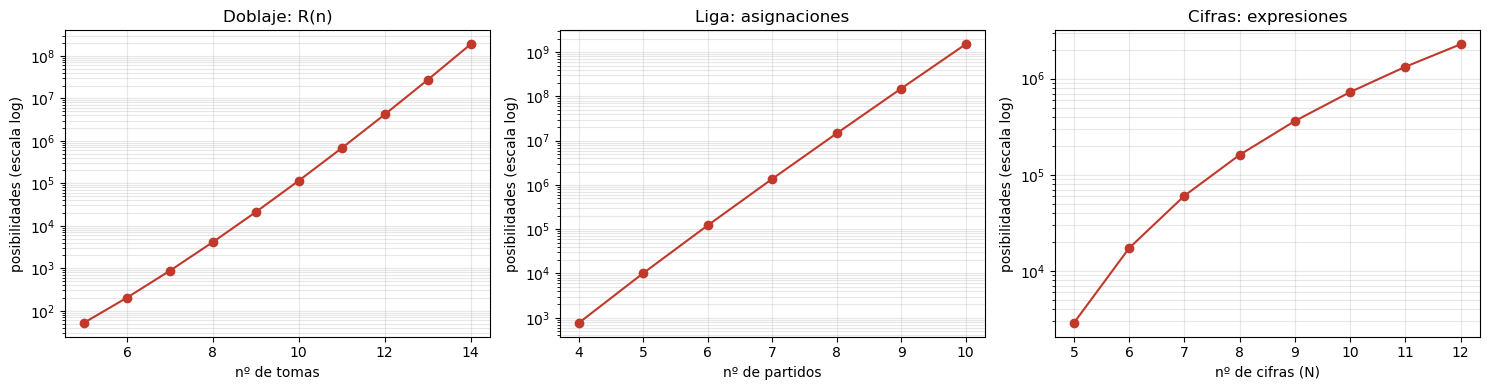

In [ ]:
print_banner("[2.2] Complejidad de la fuerza bruta: crecimiento en los 3 problemas")

print("\n--- Doblaje: crecimiento de R(n) al crecer el nº de tomas ---")
ns_doblaje = list(range(5, 15))
valores_doblaje = [contar_particiones(n, 6) for n in ns_doblaje]
for n, v in zip(ns_doblaje, valores_doblaje):
    print(f"n={n:2d} tomas -> R(n) = {v} particiones posibles")

print("\n--- Liga: crecimiento de asignaciones posibles ---")
ns_liga = list(range(4, 11))
valores_liga = [n * (n - 1) * (8 ** (n - 2)) for n in ns_liga]
for n, v in zip(ns_liga, valores_liga):
    print(f"n={n:2d} partidos -> {v} asignaciones posibles")

print("\n--- Cifras: crecimiento de expresiones posibles ---")
ns_cifras = list(range(5, 13))
valores_cifras = [variaciones(n, 5) * factorial(4) for n in ns_cifras]
for n, v in zip(ns_cifras, valores_cifras):
    print(f"N={n:2d} cifras disponibles -> {v} expresiones posibles")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
datos_growth = [
    (axes[0], ns_doblaje, valores_doblaje, 'Doblaje: R(n)', 'nº de tomas'),
    (axes[1], ns_liga, valores_liga, 'Liga: asignaciones', 'nº de partidos'),
    (axes[2], ns_cifras, valores_cifras, 'Cifras: expresiones', 'nº de cifras (N)'),
]
for ax, xs, ys, titulo, xlabel in datos_growth:
    ax.plot(xs, ys, marker='o', color='#c0392b')
    ax.set_yscale('log')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('posibilidades (escala log)')
    ax.set_title(titulo)
    ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

(*)Diseña un algoritmo que mejore la complejidad del algortimo por fuerza bruta. Argumenta porque crees que mejora el algoritmo por fuerza bruta

Respuesta

**Problema 1:** algoritmo voraz (cada toma va al día abierto con menor coste marginal, o abre uno nuevo) + búsqueda local con dos tipos de movimiento: mover una toma suelta a otro día, e intercambiar una toma de un día por una de otro. Ahí está el truco: mover solo no alcanza cuando los dos días ya están llenos (6 tomas) — ahí ningún movimiento de "mover" es válido, y sin el intercambio el algoritmo se queda atascado en un óptimo local peor. Es la misma idea que el operador 2-opt de vecindad para el TSP visto en el curso, aplicado acá a grupos en vez de a una ruta. Con esto se evita explorar las R(n) particiones completas.

**Problema 2:** recocido simulado (simulated annealing): parte de una asignación válida y prueba vecinos (intercambio o reasignación de horario), aceptando siempre mejoras y peores soluciones con probabilidad exp(−Δ/T) (criterio de Metropolis), enfriando T progresivamente. Evita explorar las 10×9×8^8 asignaciones completas.

**Problema 3:** dado que la fuerza bruta ya es viable, acá la mejora es de constante, no de complejidad: un evaluador incremental que aplica la precedencia de operadores directamente, sin `eval()` ni construcción de strings — mismo resultado, más rápido en la práctica.

In [ ]:
# --- Problema 1: algoritmo voraz + búsqueda local (mover + intercambiar) ---
def algoritmo_voraz_doblaje(tomas, tomas_bitmask, max_dia=6):
    dias = []
    for toma in tomas:
        mejor_dia, mejor_incremento = None, None
        for dia in dias:
            if len(dia) < max_dia:
                incremento = coste_dia(dia + [toma], tomas_bitmask) - coste_dia(dia, tomas_bitmask)
                if mejor_incremento is None or incremento < mejor_incremento:
                    mejor_incremento, mejor_dia = incremento, dia
        if mejor_dia is not None:
            mejor_dia.append(toma)
        else:
            dias.append([toma])
    return dias

def busqueda_local_doblaje(dias, tomas_bitmask, max_dia=6, max_iter=1000):
    # Dos tipos de movimiento: (a) MOVER una toma suelta a otro día con hueco
    # libre, (b) INTERCAMBIAR una toma de un día por una de otro (el mismo
    # principio que el operador 2-opt de vecindad visto en el curso). El
    # intercambio hace falta porque, cuando los dos días ya están llenos
    # (6 tomas), ningún "mover" es posible; sin ese movimiento el algoritmo
    # se queda atascado en un óptimo local peor. Verificado con los datos
    # reales: solo con "mover" el coste queda en 38, con el intercambio
    # agregado baja a 30.
    dias = [list(d) for d in dias]
    mejor_coste = sum(coste_dia(d, tomas_bitmask) for d in dias)
    mejorado, it = True, 0
    while mejorado and it < max_iter:
        mejorado = False
        it += 1
        for i, j in itertools.combinations(range(len(dias)), 2):
            # a) mover, en ambos sentidos
            for origen, destino in ((i, j), (j, i)):
                for toma in list(dias[origen]):
                    if len(dias[destino]) < max_dia:
                        dias[origen].remove(toma); dias[destino].append(toma)
                        nuevo_coste = sum(coste_dia(d, tomas_bitmask) for d in dias if d)
                        if nuevo_coste < mejor_coste:
                            mejor_coste, mejorado = nuevo_coste, True
                        else:
                            dias[destino].remove(toma); dias[origen].append(toma)
            # b) intercambiar una toma de i por una de j
            for toma_i in list(dias[i]):
                for toma_j in list(dias[j]):
                    # si alguna de las dos tomas ya se movió en un intercambio
                    # anterior de esta misma pasada, el snapshot quedó viejo
                    # y se salta sin más
                    if toma_i not in dias[i] or toma_j not in dias[j]:
                        continue
                    dias[i].remove(toma_i); dias[j].remove(toma_j)
                    dias[i].append(toma_j); dias[j].append(toma_i)
                    nuevo_coste = sum(coste_dia(d, tomas_bitmask) for d in dias if d)
                    if nuevo_coste < mejor_coste:
                        mejor_coste, mejorado = nuevo_coste, True
                    else:
                        dias[i].remove(toma_j); dias[j].remove(toma_i)
                        dias[i].append(toma_i); dias[j].append(toma_j)
    return [d for d in dias if d], mejor_coste

def algoritmo_mejorado_doblaje(tomas, tomas_bitmask, max_dia=6, seed=42):
    tomas = list(tomas)
    random.Random(seed).shuffle(tomas)
    return busqueda_local_doblaje(algoritmo_voraz_doblaje(tomas, tomas_bitmask, max_dia), tomas_bitmask, max_dia)

dias_mejorado, coste_mejorado = algoritmo_mejorado_doblaje(subset_bruta, tomas_bitmask)
print(f"[Problema 1 - Doblaje] Mejorado ({len(subset_bruta)} tomas) -> coste = {coste_mejorado} (óptimo FB = {coste_opt})")
print()

# --- Problema 2: recocido simulado ---
def asignacion_inicial_valida(n_partidos, seed=None):
    rng = random.Random(seed)
    indices = list(range(n_partidos))
    i_viernes, i_lunes = rng.sample(indices, 2)
    asignacion = [None] * n_partidos
    asignacion[i_viernes], asignacion[i_lunes] = "V20", "L20"
    for i in indices:
        if asignacion[i] is None:
            asignacion[i] = rng.choice(HORARIOS_LIBRES)
    return asignacion

def vecino_liga(asignacion, rng):
    nueva = list(asignacion)
    libres = [i for i, h in enumerate(nueva) if h not in ("V20", "L20")]
    if rng.random() < 0.5 and len(libres) >= 2:
        i, j = rng.sample(libres, 2)
        nueva[i], nueva[j] = nueva[j], nueva[i]
    else:
        i = rng.choice(libres)
        nueva[i] = rng.choice(HORARIOS_LIBRES)
    return nueva

def recocido_simulado_liga(partidos, T0=1.0, alpha=0.995, iteraciones=3000, seed=42):
    rng = random.Random(seed)
    actual = asignacion_inicial_valida(len(partidos), seed=seed)
    audiencia_actual = audiencia_jornada(partidos, actual)
    mejor, audiencia_mejor = list(actual), audiencia_actual
    T = T0
    for _ in range(iteraciones):
        candidata = vecino_liga(actual, rng)
        audiencia_candidata = audiencia_jornada(partidos, candidata)
        delta = audiencia_actual - audiencia_candidata
        if delta < 0 or rng.random() < math.exp(-delta / max(T, 1e-9)):
            actual, audiencia_actual = candidata, audiencia_candidata
            if audiencia_actual > audiencia_mejor:
                mejor, audiencia_mejor = list(actual), audiencia_actual
        T *= alpha
    return mejor, audiencia_mejor

_, audiencia_rs = recocido_simulado_liga(partidos_ejemplo)
print(f"[Problema 2 - Liga] Recocido simulado -> audiencia = {fmt_dec(audiencia_rs, 3)}")
print()

# --- Problema 3: evaluador incremental (mejora de constante, no de complejidad asintótica) ---
def buscar_maximo_minimo(cifras_disponibles=range(1, 10), operadores=('+', '-', '*', '/')):
    alcanzables = set()
    for cifras in itertools.permutations(cifras_disponibles, 5):
        for ops in itertools.permutations(operadores):
            resultado = evaluar_incremental(cifras, ops)
            if resultado == int(resultado):
                alcanzables.add(int(resultado))
    return alcanzables

alcanzables_v2 = buscar_maximo_minimo()
print(f"[Problema 3 - Cifras] Evaluador incremental -> coincide con fuerza bruta: {alcanzables_v2 == alcanzables}")

[Problema 1 - Doblaje] Mejorado (8 tomas) -> coste = 12 (óptimo FB = 12)

[Problema 2 - Liga] Recocido simulado -> audiencia = 6,283



[Problema 3 - Cifras] Evaluador incremental -> coincide con fuerza bruta: True


(*)Calcula la complejidad del algoritmo

Respuesta

**Problema 1:** voraz O(n²) + búsqueda local O(k·d²·max_dia²) por pasada (k pasadas acotadas, d≤n días, max_dia=6 constante). El término de intercambio suma un factor max_dia² frente a una versión que solo mueve, pero como max_dia es constante la clase de complejidad sigue siendo polinómica en n. Frente a la superexponencial de la fuerza bruta la diferencia es abismal.

**Problema 2:** O(iteraciones·n), con iteraciones constante — lineal en el número de partidos, frente a la exponencial de la fuerza bruta.

**Problema 3:** misma clase O(362880) que la fuerza bruta, no cambia asintóticamente, pero con una constante bastante menor por evaluación al sacarse de encima `eval()` y la construcción de strings.

┌───────────────────────────────────────────────────────────────────────────┐
│ [2.4] Complejidad empírica de los algoritmos mejorados en los 3 problemas │
└───────────────────────────────────────────────────────────────────────────┘

--- Doblaje: tiempo del algoritmo mejorado al crecer el nº de tomas ---
n_tomas=10 -> tiempo = 0,0003s
n_tomas=15 -> tiempo = 0,0013s
n_tomas=20 -> tiempo = 0,0017s
n_tomas=25 -> tiempo = 0,0028s
n_tomas=30 -> tiempo = 0,0062s

--- Liga: tiempo del recocido simulado al crecer el nº de partidos ---
n_partidos=10 -> tiempo = 0,039s
n_partidos=20 -> tiempo = 0,077s


n_partidos=40 -> tiempo = 0,170s


n_partidos=80 -> tiempo = 0,279s

--- Cifras: eval() vs evaluador incremental (misma clase de complejidad, distinta constante) ---


Con eval():            213,68s
Evaluador incremental: 0,93s
Speedup: 229,61x


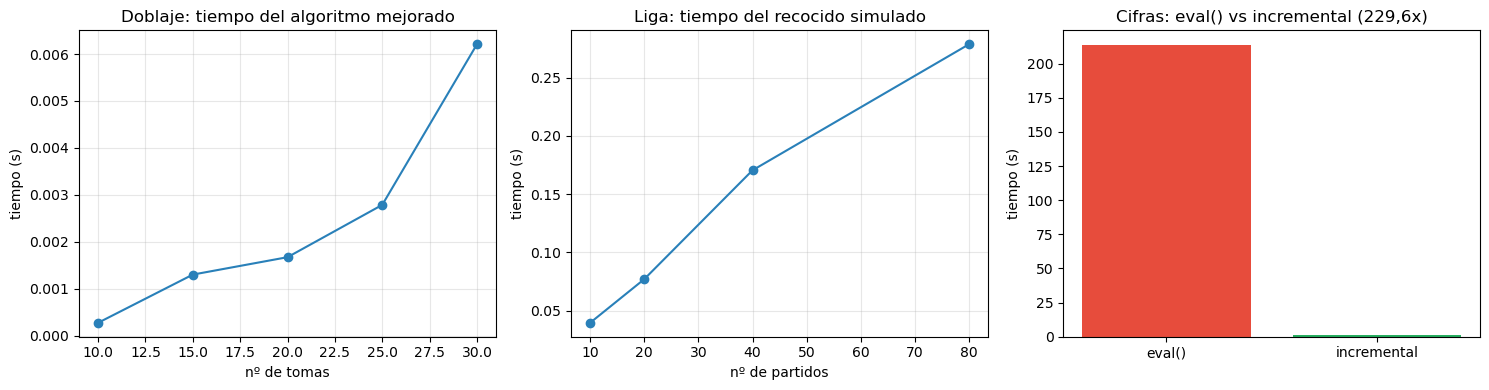

In [ ]:
import time

print_banner("[2.4] Complejidad empírica de los algoritmos mejorados en los 3 problemas")

print("\n--- Doblaje: tiempo del algoritmo mejorado al crecer el nº de tomas ---")
ks_doblaje = [10, 15, 20, 25, 30]
tiempos_doblaje = []
for k in ks_doblaje:
    subset_tiempo = list(df.index)[:k]
    t0 = time.time()
    algoritmo_mejorado_doblaje(subset_tiempo, tomas_bitmask)
    t1 = time.time()
    tiempos_doblaje.append(t1 - t0)
    print(f"n_tomas={k:2d} -> tiempo = {fmt_dec(tiempos_doblaje[-1], 4)}s")

print("\n--- Liga: tiempo del recocido simulado al crecer el nº de partidos ---")
categorias_pool = ("A",) * 3 + ("B",) * 11 + ("C",) * 6
rng_tiempo = random.Random(1)
ns_liga_t = [10, 20, 40, 80]
tiempos_liga = []
for n in ns_liga_t:
    jornada_tiempo = [(rng_tiempo.choice(categorias_pool), rng_tiempo.choice(categorias_pool)) for _ in range(n)]
    t0 = time.time()
    recocido_simulado_liga(jornada_tiempo, iteraciones=3000, seed=1)
    t1 = time.time()
    tiempos_liga.append(t1 - t0)
    print(f"n_partidos={n:2d} -> tiempo = {fmt_dec(tiempos_liga[-1], 3)}s")

print("\n--- Cifras: eval() vs evaluador incremental (misma clase de complejidad, distinta constante) ---")
t0 = time.time()
explorar_fuerza_bruta()
t1 = time.time()
tiempo_eval = t1 - t0

t0 = time.time()
buscar_maximo_minimo()
t1 = time.time()
tiempo_incremental = t1 - t0

print(f"Con eval():            {fmt_dec(tiempo_eval, 2)}s")
print(f"Evaluador incremental: {fmt_dec(tiempo_incremental, 2)}s")
print(f"Speedup: {fmt_dec(tiempo_eval / tiempo_incremental, 2)}x")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ks_doblaje, tiempos_doblaje, marker='o', color='#2980b9')
axes[0].set_xlabel('nº de tomas')
axes[0].set_ylabel('tiempo (s)')
axes[0].set_title('Doblaje: tiempo del algoritmo mejorado')
axes[0].grid(True, alpha=0.3)

axes[1].plot(ns_liga_t, tiempos_liga, marker='o', color='#2980b9')
axes[1].set_xlabel('nº de partidos')
axes[1].set_ylabel('tiempo (s)')
axes[1].set_title('Liga: tiempo del recocido simulado')
axes[1].grid(True, alpha=0.3)

axes[2].bar(['eval()', 'incremental'], [tiempo_eval, tiempo_incremental], color=['#e74c3c', '#27ae60'])
axes[2].set_ylabel('tiempo (s)')
axes[2].set_title(f'Cifras: eval() vs incremental ({fmt_dec(tiempo_eval/tiempo_incremental,1)}x)')

plt.tight_layout()
plt.show()

Según el problema (y tenga sentido), diseña un juego de datos de entrada aleatorios

Respuesta

**Problema 1:** generador de matrices actor×toma aleatorias (parámetros: nº actores, nº tomas, probabilidad de participación), cuidando que no queden filas ni columnas vacías.

**Problema 2:** generador de jornadas aleatorias que empareja categorías de equipos al azar, respetando la proporción real (3 A, 11 B, 6 C).

**Problema 3:** generalización a N cifras disponibles en vez de fijas a 9, reutilizando los mismos 4 operadores.

In [ ]:
# --- Problema 1 ---
def generar_datos_doblaje(n_actores=10, n_tomas=30, prob=0.25, seed=None):
    rng = np.random.default_rng(seed)
    matriz = (rng.random((n_tomas, n_actores)) < prob).astype(int)
    for i in range(n_tomas):
        if matriz[i].sum() == 0:
            matriz[i, rng.integers(0, n_actores)] = 1
    for j in range(n_actores):
        if matriz[:, j].sum() == 0:
            matriz[rng.integers(0, n_tomas), j] = 1
    return pd.DataFrame(matriz, index=range(1, n_tomas + 1), columns=range(1, n_actores + 1))

# --- Problema 2 ---
def generar_jornada_aleatoria(n_partidos=10, categorias_pool=("A",) * 3 + ("B",) * 11 + ("C",) * 6, seed=None):
    rng = random.Random(seed)
    return [(rng.choice(categorias_pool), rng.choice(categorias_pool)) for _ in range(n_partidos)]

# --- Problema 3 ---
def generar_problema_cifras(n_max=9, operadores_base=('+', '-', '*', '/')):
    return list(range(1, n_max + 1)), operadores_base

print("Generadores de datos aleatorios definidos para los 3 problemas.")

Generadores de datos aleatorios definidos para los 3 problemas.


Aplica el algoritmo al juego de datos generado

Respuesta

Cada algoritmo mejorado se aplica sobre los datos reales del enunciado y sobre datos generados de tamaño creciente (ver celda de código): voraz + búsqueda local con intercambio sobre matrices actor×toma más grandes en Doblaje, recocido simulado sobre jornadas con más partidos en Liga, y el evaluador incremental sobre conjuntos de más cifras disponibles en Cifras.

--- Problema 1: datos reales + escalabilidad ---
[Problema 1 - Doblaje] Datos reales -> 5 días, coste = 30
[Problema 1 - Doblaje] n_tomas=30 -> coste = 28
[Problema 1 - Doblaje] n_tomas=60 -> coste = 53

--- Problema 2: datos reales + escalabilidad ---


[Problema 2 - Liga] n_partidos=10 -> audiencia = 6,32 Millones


[Problema 2 - Liga] n_partidos=20 -> audiencia = 10,61 Millones


[Problema 2 - Liga] n_partidos=40 -> audiencia = 13,18 Millones

--- Problema 3: escalabilidad ---


[Problema 3 - Cifras] N=7 -> 83 valores alcanzables (min=-39, max=45)


[Problema 3 - Cifras] N=8 -> 113 valores alcanzables (min=-53, max=60)


[Problema 3 - Cifras] N=9 -> 147 valores alcanzables (min=-69, max=77)


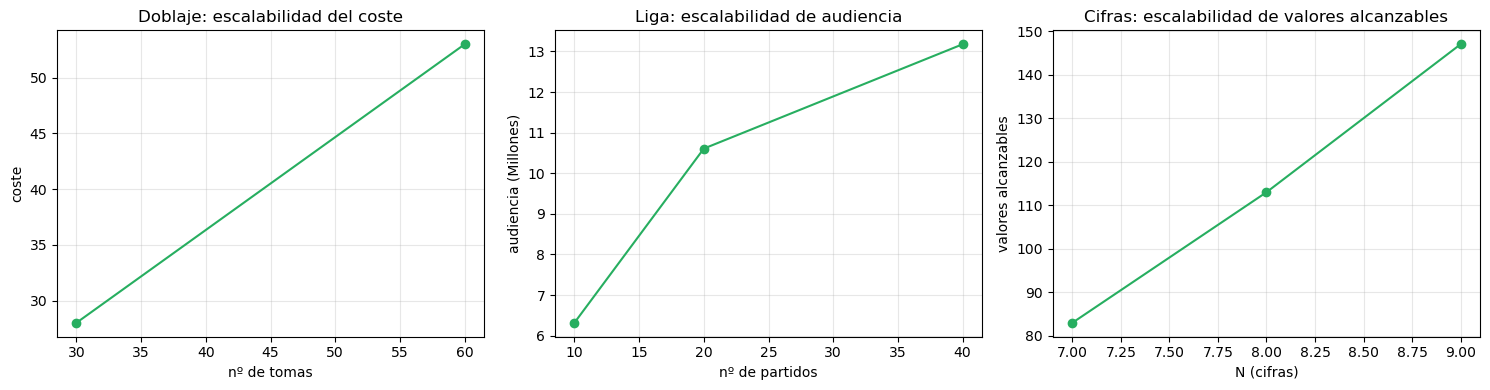

In [ ]:
print("--- Problema 1: datos reales + escalabilidad ---")
dias_reales, coste_real = algoritmo_mejorado_doblaje(list(df.index), tomas_bitmask)
print(f"[Problema 1 - Doblaje] Datos reales -> {len(dias_reales)} días, coste = {coste_real}")
ns_doblaje_esc = [30, 60]
costes_doblaje_esc = []
for n_tomas_test in ns_doblaje_esc:
    df_test = generar_datos_doblaje(n_tomas=n_tomas_test, seed=0)
    bitmask_test = {t: int(''.join(str(int(v)) for v in f), 2) for t, f in df_test.iterrows()}
    _, coste_test = algoritmo_mejorado_doblaje(list(df_test.index), bitmask_test)
    costes_doblaje_esc.append(coste_test)
    print(f"[Problema 1 - Doblaje] n_tomas={n_tomas_test} -> coste = {coste_test}")
print()

print("--- Problema 2: datos reales + escalabilidad ---")
ns_liga_esc = [10, 20, 40]
audiencias_liga_esc = []
for n in ns_liga_esc:
    jornada = generar_jornada_aleatoria(n_partidos=n, seed=1)
    _, audiencia_n = recocido_simulado_liga(jornada, iteraciones=3000, seed=1)
    audiencias_liga_esc.append(audiencia_n)
    print(f"[Problema 2 - Liga] n_partidos={n} -> audiencia = {fmt_dec(audiencia_n, 2)} Millones")
print()

print("--- Problema 3: escalabilidad ---")
ns_cifras_esc = [7, 8, 9]
valores_cifras_esc = []
for n_max in ns_cifras_esc:
    cifras_disp, ops = generar_problema_cifras(n_max=n_max)
    alcanzables_n = buscar_maximo_minimo(cifras_disponibles=cifras_disp, operadores=ops)
    valores_cifras_esc.append(len(alcanzables_n))
    print(f"[Problema 3 - Cifras] N={n_max} -> {len(alcanzables_n)} valores alcanzables "
          f"(min={min(alcanzables_n)}, max={max(alcanzables_n)})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ns_doblaje_esc, costes_doblaje_esc, marker='o', color='#27ae60')
axes[0].set_xlabel('nº de tomas'); axes[0].set_ylabel('coste'); axes[0].set_title('Doblaje: escalabilidad del coste')
axes[0].grid(True, alpha=0.3)

axes[1].plot(ns_liga_esc, audiencias_liga_esc, marker='o', color='#27ae60')
axes[1].set_xlabel('nº de partidos'); axes[1].set_ylabel('audiencia (Millones)'); axes[1].set_title('Liga: escalabilidad de audiencia')
axes[1].grid(True, alpha=0.3)

axes[2].plot(ns_cifras_esc, valores_cifras_esc, marker='o', color='#27ae60')
axes[2].set_xlabel('N (cifras)'); axes[2].set_ylabel('valores alcanzables'); axes[2].set_title('Cifras: escalabilidad de valores alcanzables')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Enumera las referencias que has utilizado(si ha sido necesario) para llevar a cabo el trabajo

Respuesta

- Duarte, A. (2008). *Metaheurísticas*. Madrid: Dykinson (búsqueda local y recocido simulado).
- Kirkpatrick, S., Gelatt, C.D., y Vecchi, M.P. (1983). *Optimization by Simulated Annealing*.
- Documentación oficial de Python: `itertools`, `functools.lru_cache`, `numpy.random`, `random`, `math`.
- Resto de bibliografía del curso: Brassard y Bratley (1997), Guerequeta y Vallecillo (2000), Lee et al. (2005), Pérez Aguila (2012).

Describe brevemente las lineas de como crees que es posible avanzar en el estudio del problema. Ten en cuenta incluso posibles variaciones del problema y/o variaciones al alza del tamaño

Respuesta

**Problema 1:** para escalar a más actores o tomas, conviene aplicar metaheurísticas más fuertes (recocido simulado, algoritmos genéticos) en vez de quedarse solo con voraz más búsqueda local. También vale la pena modelar tarifas distintas por actor o disponibilidad limitada en ciertos días: el modelo actual asume que todos cuestan lo mismo y están siempre disponibles.

**Problema 2:** con más equipos, categorías o competiciones simultáneas, GRASP o los algoritmos genéticos escalan mejor que ajustar la solución manualmente. También se podría ponderar la audiencia según la fecha del calendario, ya que no es lo mismo la jornada 1 que la última.

**Problema 3:** la pregunta de si todos los enteros del rango son alcanzables ya está respondida con evidencia (ver celda de código): con las 9 cifras del enunciado, **sí**, los 147 enteros entre -69 y 77 son todos alcanzables, sin huecos. Pero con menos cifras disponibles sí hay huecos — el hueco se va cerrando a medida que crece N hasta desaparecer en N=9. Las líneas de continuación son otras: permitir paréntesis, repetir cifras u operadores, o incorporar más operadores.